# Segmentation accuracy and phenotype fidelity (§5.2)

Level 2: did segmentation preserve marker measurements and cellular identity? For every scored cell of the test
slide, the seven phenotype markers of the panel (PanCK, CD45, CD3, CD4, CD8, FOXP3, uPAR) are measured inside the
expert boundary and inside the matched predicted boundary; both are
gated with the panel's hierarchy (`configs/panel.yaml`) and identical thresholds — the gates calibrated on the biologist's
tags in notebook 09, carried to this slide in normalized units — and the disagreements are stratified by the error class of notebook 02,
tracing the chain boundary error → marker distortion → phenotype error. The sensitive probes are two-marker cell
states: the PanCK⁺uPAR⁺ epithelial state only needs the second marker diluted below its gate to be lost.

Needs notebook 02 (`taxonomy_<run>.csv`, every seed). Writes `cells_expert.csv`, `cells_<run>.csv` (and
`cells_<method>.csv` for the drawn seed), `phenotype_summary.csv` (mean over seeds) and `phenotype_summary_sd.csv` for
notebooks 04–05.

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest, apply_qc_policy
from mxdata.data import LiveSource
from mxseg.evaluate import split_regions_of, read_prediction

# ---- edit here ---------------------------------------------------------------------------------------------------------
METHODS_ALL = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft",
               "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]
SHOW_METHODS = ["cellpose", "cellpose_ft", "sam3", "dinov3b_frozen", "unet_flows", "kodiakb_flows"]
SEED = 0                                        # the seed drawn in every figure; every table pools the seeds (mean ± std)
TEST_SLIDE = "SLIDE-0236"                       # the paper's Slide 2: every §5 analysis runs on it; the other held-out slide (SLIDE-0233,
                                                # Slide 3) is scored in notebook 02's Slide-3 table from the stored per-region results
# METHODS_ALL: the paper's order (ViT-B rows, 10-epoch budget, 3 seeds); a method enters once its test-slide predictions exist.
# SHOW_METHODS: the image figures.
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
ANALYSIS.mkdir(parents=True, exist_ok=True)
PRED = REPO / "outputs" / "region" / "test"        # mxseg eval -b configs/baselines/<method>.yaml --split test --unit region --store-predictions
cfg = load_config(REPO / "configs" / "dataset.yaml")

LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "cellpose": "Cellpose-SAM, zero-shot",
         "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg", "sam3": "SAM 3, exemplar", "sam3_text": "SAM 3, text",
         "sam2": "SAM 2.1, prototype",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "dinov3_frozen": "DINOv3 S/16, frozen", "kodiak_frozen": "KODIAK S/16, frozen"}
SHORT = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B", "dinov3b_flows": "DINOv3 B", "kodiakb_frozen": "KODIAK B frozen",
         "dinov3b_frozen": "DINOv3 B frozen", "cellpose_ft": "Cellpose adapted", "cellpose": "Cellpose-SAM 0-shot", "cpdino": "Cellpose-DINO 0-shot",
         "instanseg": "InstanSeg", "sam3": "SAM 3 exemplar", "sam3_text": "SAM 3 text", "sam2": "SAM 2.1",
         "kodiak_flows": "KODIAK S", "dinov3_flows": "DINOv3 S", "dinov3_frozen": "DINOv3 S frozen", "kodiak_frozen": "KODIAK S frozen"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E", "dinov3b_frozen": "#D3BF8C",
          "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B",
          "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "dinov3_frozen": "#D3BF8C", "kodiak_frozen": "#DF959E"}   # the paper's swatches; frozen = tints
INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PHENO_COLOR = {"Epithelial": "#2A78D6", "Immune": "#C43E4E", "Other": "#AEB2B8"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    """Nature-style bold panel letter, outside the axes' top-left corner."""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    """A short label inside an image panel (region, method) — never a sentence."""
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def barh_clean(ax):
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def short(key):
    return key.split("_")[-1]

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, (lo, hi))
    return np.clip((img - a) / max(b - a, 1e-6), 0, 1)

per_slide = split_regions_of(DEFAULT_DATASET, "test", cfg.slides)          # the protocol: held-out test slides, every region reviewed
assert TEST_SLIDE in per_slide, f"{TEST_SLIDE} is not a test slide of the split: {list(per_slide)}"
OTHER_TEST = [s for s in per_slide if s != TEST_SLIDE]                     # also held out (Slide 3): never pooled with TEST_SLIDE here
paths, mx, _ = ingest(TEST_SLIDE, None)
ids = sorted(per_slide[TEST_SLIDE])
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}
src = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
TEST = {}                                          # key -> DAPI, labels (expert-flagged nuclei zeroed) and their ignore mask
for key in src.keys:
    rs = src.load(key)
    labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    r = regions[int(key.split("_R")[-1])]
    TEST[key] = dict(dapi=rs.image[0], labels=labels, ignore=ignore, region=r, has_qc=bool(r.has_qc))
PX_UM = float(mx.pixel_size_um or 0.325)

def runs_of(m):
    """The stored, complete runs of a method (every test region predicted): <method>_s<seed> for trained rows, the bare name for zero-shot rows."""
    names = sorted(d.name for d in PRED.glob(f"{m}_s[0-9]*") if d.is_dir()) or ([m] if (PRED / m).is_dir() else [])
    return [r for r in names if all((PRED / r / f"{k}.npz").is_file() for k in TEST)]
RUNS = {m: runs_of(m) for m in METHODS_ALL if runs_of(m)}
METHODS = list(RUNS)
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}   # the run drawn in the figures
if not METHODS:
    raise FileNotFoundError(f"no complete test-slide predictions under {PRED.relative_to(REPO)} — scripts/finetune_all.sh evaluates every run:  "
                            "mxseg eval -b configs/baselines/<method>.yaml --split test --unit region")
if len(METHODS) < len(METHODS_ALL):
    print("not evaluated yet, skipped:", ", ".join(LABEL[m] for m in METHODS_ALL if m not in METHODS))
SHOW = [m for m in SHOW_METHODS if m in METHODS]

def pred_of(run, key):
    """A stored instance map: ``run`` is a run name (<method>_s<seed>, or the bare name of a zero-shot row) or a method (its drawn run)."""
    return read_prediction(PRED / RUN.get(run, run) / f"{key}.npz")

def tag(key):
    return short(key) + ("*" if TEST[key]["has_qc"] else "")

def scalebar(ax, npx, um=50, color="white"):
    L = um / PX_UM
    x1, y = npx * 0.96, npx * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.2, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx * 0.025, f"{um} µm", color=color, ha="center", va="bottom", fontsize=7)

print(f"test slide {TEST_SLIDE}: {len(TEST)} regions ({', '.join(tag(k) for k in TEST)}; * = reviewed) | methods (seeds): "
      + ", ".join(f"{LABEL[m]} ({len(RUNS[m])})" for m in METHODS) + f" | figures draw seed {SEED}"
      + (f" | also held out, analysed separately: {', '.join(OTHER_TEST)}" if OTHER_TEST else ""))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


test slide SLIDE-0236: 6 regions (R01*, R02*, R03*, R04*, R05*, R06*; * = reviewed) | methods (seeds): U-Net (3), KODIAK B/16 (3), DINOv3 B/16 (3), KODIAK B/16, frozen (3), DINOv3 B/16, frozen (3), Cellpose, adapted (3), Cellpose-SAM, zero-shot (1), Cellpose (DINOv3), zero-shot (1), InstanSeg (1), SAM 3, exemplar (1), SAM 3, text (1), SAM 2.1, prototype (1) | figures draw seed 0 | also held out, analysed separately: SLIDE-0233


In [2]:
from mxdata.pipeline.stats import NormStats
from mxseg.analysis import assign_phenotypes, cell_marker_table, gate_phenotypes, load_panel, phenotype_gates

PANEL = ["PanCK", "CD45", "CD3", "CD4", "CD8", "FOXP3", "uPAR"]
MARK = {key: mx.read_region(T["region"].box, markers=PANEL, level=0).astype(np.float32) for key, T in TEST.items()}
have = {m: [run for run in RUNS[m] if (ANALYSIS / f"taxonomy_{run}.csv").is_file()] for m in METHODS}
skipped = [run for m in METHODS for run in RUNS[m] if run not in have[m]]
if skipped:
    print("no taxonomy table yet — evaluated after notebook 02 ran; rerun 02 to include:", ", ".join(skipped))
RUNS = {m: have[m] for m in METHODS if have[m]}
METHODS = list(RUNS)
if not METHODS:
    raise FileNotFoundError("run notebook 02 first — no taxonomy tables under outputs/analysis")
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}
SHOW = [m for m in SHOW_METHODS if m in METHODS]
tax = {run: pd.read_csv(ANALYSIS / f"taxonomy_{run}.csv") for m in METHODS for run in RUNS[m]}

expert = []                                                                    # the reference: marker means inside every CONFIRMED expert cell
for key, T in TEST.items():
    confirmed = np.where(T["ignore"], 0, T["labels"])                          # flagged cells are HALO's errors: not part of the reference
    t = cell_marker_table(confirmed, MARK[key], PANEL)
    t["region"] = key
    expert.append(t)
expert = pd.concat(expert, ignore_index=True)
PANELCFG = load_panel(REPO / "configs" / "panel.yaml")                        # the biologist's phenotypes: one marker each, hierarchical
assert isinstance(PANELCFG.gates, dict), "configs/panel.yaml must carry the calibrated gate values (notebook 09) — no automatic gating here"
_st = NormStats.load(DEFAULT_DATASET / TEST_SLIDE / "stats.json")
NORMS_T = {mk: (float(_st.lo[mk]), float(_st.hi[mk])) for mk in PANELCFG.gate_markers}
THR_T = phenotype_gates(expert, PANELCFG, norms=NORMS_T)                      # the panel's gates (slide-normalized units) in this slide's raw counts
THR = {mk: THR_T[mk] for mk in ("PanCK", "CD45")}                              # the lineage gates are the same thresholds
expert["pheno"] = gate_phenotypes(expert, THR)
expert["cell_type"], expert["lineage"] = assign_phenotypes(expert, PANELCFG, THR_T)
expert.to_csv(ANALYSIS / "cells_expert.csv", index=False)

cells, cells_run = {}, {}                                                      # matched cells: expert-boundary and predicted-boundary measurements
for m in METHODS:
    for run in RUNS[m]:
        frames = []
        for key, T in TEST.items():
            pairs = tax[run][(tax[run].region == key) & (tax[run].pred_id > 0)][["gt_id", "pred_id", "cls"]]
            pt = cell_marker_table(pred_of(run, key), MARK[key], PANEL, ids=pairs.pred_id.unique())
            pt = pairs.merge(pt.rename(columns={"id": "pred_id"}), on="pred_id")
            et = expert[expert.region == key][["id"] + PANEL].rename(columns={"id": "gt_id"})
            j = pt.merge(et, on="gt_id", suffixes=("_pred", "_expert"))
            j["region"] = key
            frames.append(j)
        c = pd.concat(frames, ignore_index=True)
        c["pheno_pred"] = gate_phenotypes(c.rename(columns={"PanCK_pred": "PanCK", "CD45_pred": "CD45"}), THR)
        c["pheno_expert"] = gate_phenotypes(c.rename(columns={"PanCK_expert": "PanCK", "CD45_expert": "CD45"}), THR)
        c["type_expert"], _ = assign_phenotypes(c.rename(columns={f"{mk}_expert": mk for mk in PANEL}), PANELCFG, THR_T)
        c["type_pred"], _ = assign_phenotypes(c.rename(columns={f"{mk}_pred": mk for mk in PANEL}), PANELCFG, THR_T)
        c.to_csv(ANALYSIS / f"cells_{run}.csv", index=False)
        cells_run[run] = c
        if run == RUN[m]:
            cells[m] = c
            c.to_csv(ANALYSIS / f"cells_{m}.csv", index=False)                 # the drawn seed, under the method's name (notebooks 04-05)
print(f"{len(expert)} confirmed expert cells (flagged cells excluded) | lineage gates (the panel's calibrated gates, this slide's counts): " + ", ".join(f"{k} {v:.0f}" for k, v in THR.items()) +
      " | " + ", ".join(f"{k} {v}" for k, v in expert.pheno.value_counts().items()))
print(f"phenotypes: " + ", ".join(PANELCFG.names) + f" | gates: " + ", ".join(f"{m} {v:.0f}" for m, v in THR_T.items()))

6152 confirmed expert cells (flagged cells excluded) | lineage gates (the panel's calibrated gates, this slide's counts): PanCK 385, CD45 621 | Other 2455, Immune 1870, Epithelial 1827
phenotypes: Epithelial, uPAR+ epithelial, T cell, Treg, CD8+ T cell, CD4+ T cell, Immune | gates: PanCK 385, uPAR 2244, CD3 1502, FOXP3 749, CD8 558, CD4 4018, CD45 621


## 1. Marker quantification under predicted boundaries

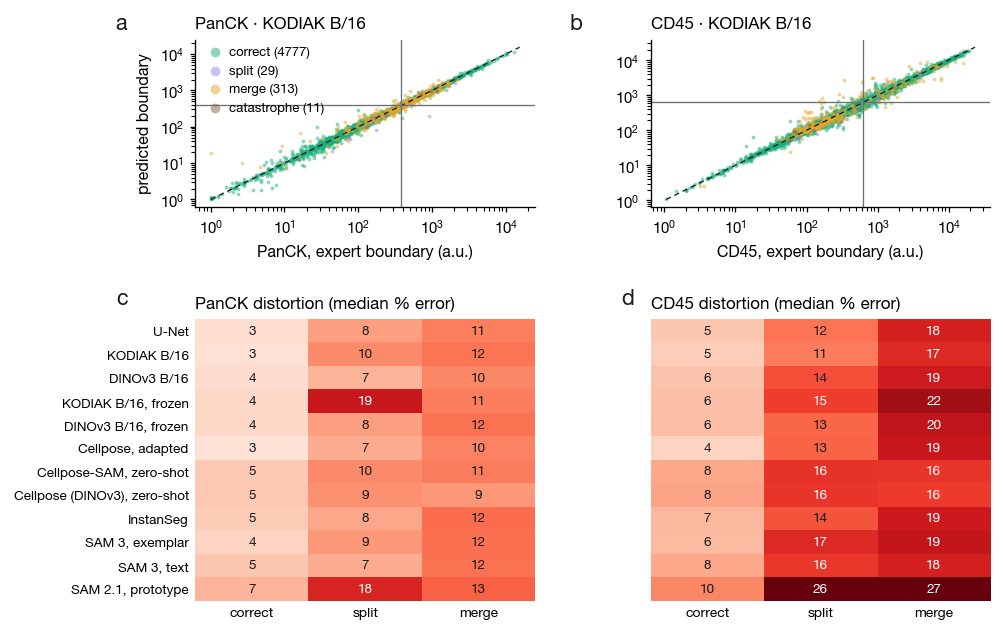

In [3]:
CLS_COLOR = {"correct": "#1BAF7A", "split": "#9A86E0", "merge": "#E4A72E", "catastrophe": "#8B5E3C", "missed": "#E34948"}
CLASSES3 = ["correct", "split", "merge"]                                       # catastrophes are too few for a median
QUANT = SHOW[-1] if SHOW else METHODS[0]                                       # the method of the scatter panels
fig = plt.figure(figsize=(7.6, 5.4))
gs = fig.add_gridspec(2, 2, hspace=0.5, wspace=0.34, height_ratios=[1.35, 0.35 + 0.16 * len(METHODS)])
for k, mk in enumerate(("PanCK", "CD45")):
    a = fig.add_subplot(gs[0, k])                                              # a, b - expert vs predicted boundary, per cell
    c = cells[QUANT]
    for cls in CLASSES3 + ["catastrophe"]:
        s_ = c[c.cls == cls]
        a.scatter(s_[f"{mk}_expert"] + 1, s_[f"{mk}_pred"] + 1, s=4, lw=0, alpha=0.5, color=CLS_COLOR[cls],
                  label=f"{cls} ({len(s_)})" if k == 0 else None, rasterized=True)
    lim = (c[f"{mk}_expert"].min() + 1, c[f"{mk}_expert"].max() * 1.2)
    a.plot(lim, lim, color=INK, lw=0.7, ls=(0, (4, 3)))
    a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel(f"{mk}, expert boundary (a.u.)"); a.set_ylabel("predicted boundary" if k == 0 else None)
    a.axvline(THR[mk], color=MUTED, lw=0.7); a.axhline(THR[mk], color=MUTED, lw=0.7)
    a.set_title(f"{mk} · {LABEL[QUANT]}")
    panel(a, "ab"[k], dx=-0.2)
    if k == 0:
        a.legend(markerscale=2.6, fontsize=7, loc="upper left", handletextpad=0.1, borderaxespad=0.1)
for k, mk in enumerate(("PanCK", "CD45")):                                     # c, d - median distortion, methods x error class
    a = fig.add_subplot(gs[1, k])
    M = np.zeros((len(METHODS), len(CLASSES3)))
    for i, mm in enumerate(METHODS):
        cc = cells[mm]
        err = (cc[f"{mk}_pred"] - cc[f"{mk}_expert"]).abs() / cc[f"{mk}_expert"].clip(lower=1)
        M[i] = 100 * err.groupby(cc.cls).median().reindex(CLASSES3).fillna(0).values
    im = a.imshow(M, cmap="Reds", vmin=0, vmax=25, aspect="auto")
    a.set_xticks(range(len(CLASSES3)), CLASSES3, fontsize=7.4)
    a.set_yticks(range(len(METHODS)), [LABEL[mm] for mm in METHODS] if k == 0 else [""] * len(METHODS), fontsize=7.2)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            a.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=7.2, color="white" if M[i, j] > 15 else INK)
    a.set_title(f"{mk} distortion (median % error)")
    for s_ in a.spines.values():
        s_.set_visible(False)
    a.tick_params(length=0)
    panel(a, "cd"[k], dx=-0.2 if k == 0 else -0.05)
plt.show()

**Figure 1 — Boundary error becomes marker distortion.** (a, b) For every matched cell of one method, the mean PanCK
and CD45 inside the expert boundary against the mean inside the predicted boundary (log axes, identity dashed, gates
gray), colored by the cell's error class from notebook 02: correct matches hug the diagonal, merges and splits measure
someone else's pixels. (c, d) The median relative error per method and error class — the distortion follows the
taxonomy exactly: a few percent for correct matches, an order of magnitude more for merges. Phenotype errors can only
arise where a distorted value crosses a gate.

## 2. Phenotype agreement

mean over seeds (std in phenotype_summary_sd.csv):
                              lineage_agreement  type_agreement  upar_state_kept  n_upar  agree_correct  agree_split  agree_merge  agree_catastrophe  agree_missed  seeds
method                                                                                                                                                                   
U-Net                                      96.3            95.0             93.8   301.7           97.1         91.9         90.3               95.2          90.1      3
KODIAK B/16                                96.7            95.5             93.6   296.3           97.5         89.2         90.6               97.6          90.4      3
DINOv3 B/16                                96.0            94.7             94.0   289.7           96.8         94.5         91.1               95.2          89.7      3
KODIAK B/16, frozen                        95.8            94.3             92.7   261.0           

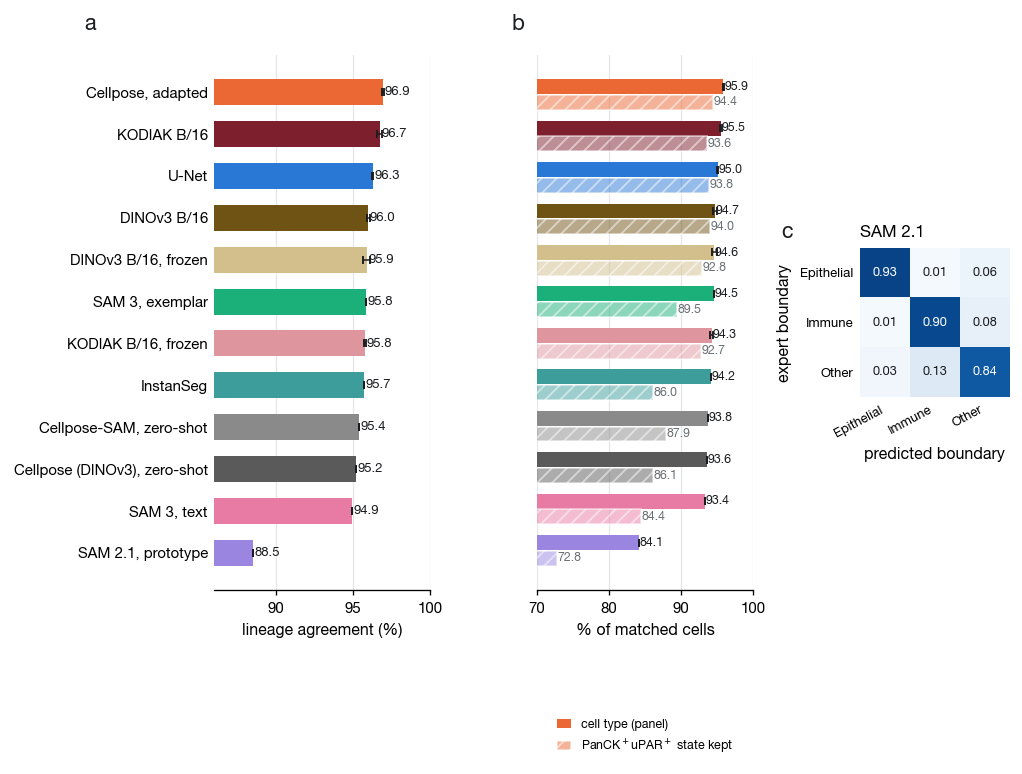

In [4]:
def summarize(c):
    ag = c.pheno_pred == c.pheno_expert
    up = c.type_expert == "uPAR+ epithelial"
    return {"lineage_agreement": 100 * ag.mean(), "type_agreement": 100 * (c.type_expert == c.type_pred).mean(),
            "upar_state_kept": 100 * (c.type_pred[up] == "uPAR+ epithelial").mean() if up.any() else np.nan, "n_upar": int(up.sum()),
            **{f"agree_{cls}": 100 * ag[c.cls == cls].mean() for cls in CLS_COLOR if (c.cls == cls).any()}}
summ_runs = pd.DataFrame([{"method": m, "run": run, **summarize(cells_run[run])} for m in METHODS for run in RUNS[m]])
num = [c_ for c_ in summ_runs.columns if c_ not in ("method", "run")]
summ = summ_runs.groupby("method", sort=False)[num].mean().loc[METHODS]                 # mean over seeds
summ_sd = summ_runs.groupby("method", sort=False)[num].std(ddof=0).loc[METHODS]
summ["seeds"] = summ_runs.groupby("method").run.count().loc[METHODS]
summ.to_csv(ANALYSIS / "phenotype_summary.csv"); summ_sd.add_suffix("_sd").to_csv(ANALYSIS / "phenotype_summary_sd.csv")
agree = {m: (cells[m].pheno_pred == cells[m].pheno_expert) for m in METHODS}
print("mean over seeds (std in phenotype_summary_sd.csv):"); print(summ.round(1).rename(index=LABEL).to_string())

order = list(summ.sort_values("lineage_agreement", ascending=False).index)
y = np.arange(len(order))[::-1]
noisy = order[-1]
fig = plt.figure(figsize=(7.6, 0.55 + 0.3 * len(order) + 1.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1.3, 0.9], wspace=0.55)
a = fig.add_subplot(gs[0])                                                     # a - lineage agreement
vals = summ.loc[order, "lineage_agreement"].values
a.barh(y, vals, color=[MCOLOR[m] for m in order], height=0.62, zorder=3, xerr=summ_sd.loc[order, "lineage_agreement"].fillna(0).values, error_kw=dict(lw=0.8, capsize=2, ecolor=INK))
for i, v in enumerate(vals):
    a.text(v + 0.1, y[i], f"{v:.1f}", va="center", fontsize=7, color=INK)
a.set_yticks(y, [LABEL[m] for m in order]); a.set_xlim(np.floor(vals.min() - 2), 100); a.set_xlabel("lineage agreement (%)")
xgrid(a); barh_clean(a)
panel(a, "a", dx=-0.55)
b = fig.add_subplot(gs[1])                                                     # b - finest level: cell type, and the two-marker state
b.barh(y + 0.19, summ.loc[order, "type_agreement"], 0.36, color=[MCOLOR[m] for m in order], zorder=3, label="cell type (panel)",
       xerr=summ_sd.loc[order, "type_agreement"].fillna(0).values, error_kw=dict(lw=0.8, capsize=2, ecolor=INK))
b.barh(y - 0.19, summ.loc[order, "upar_state_kept"], 0.36, color=[MCOLOR[m] for m in order], alpha=0.5, hatch="///", edgecolor="white",
       zorder=3, label="PanCK$^+$uPAR$^+$ state kept")
for i, m in enumerate(order):
    b.text(summ.loc[m, "type_agreement"] + 0.1, y[i] + 0.19, f"{summ.loc[m, 'type_agreement']:.1f}", va="center", fontsize=6.6, color=INK)
    if summ.loc[m, "upar_state_kept"] == summ.loc[m, "upar_state_kept"]:
        b.text(summ.loc[m, "upar_state_kept"] + 0.1, y[i] - 0.19, f"{summ.loc[m, 'upar_state_kept']:.1f}", va="center", fontsize=6.6, color=MUTED)
lo = np.nanmin(summ[["type_agreement", "upar_state_kept"]].values)
b.set_yticks([]); b.set_xlim(np.floor(lo - 2), 100); b.set_xlabel("% of matched cells")
b.legend(fontsize=6.6, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1, handlelength=1.2)
xgrid(b); barh_clean(b)
panel(b, "b", dx=-0.06)
c = fig.add_subplot(gs[2])                                                     # c - where the flips go, noisiest method
conf = pd.crosstab(cells[noisy].pheno_expert, cells[noisy].pheno_pred, normalize="index").reindex(index=list(PHENO_COLOR), columns=list(PHENO_COLOR)).fillna(0)
c.imshow(conf.values, cmap="Blues", vmin=0, vmax=1)
c.set_xticks(range(3), conf.columns, rotation=28, ha="right", fontsize=7); c.set_yticks(range(3), conf.index, fontsize=7)
for i in range(3):
    for j in range(3):
        c.text(j, i, f"{conf.values[i, j]:.2f}", ha="center", va="center", fontsize=6.8, color="white" if conf.values[i, j] > 0.5 else INK)
c.set_xlabel("predicted boundary"); c.set_ylabel("expert boundary")
c.set_title(SHORT[noisy])
for s_ in c.spines.values():
    s_.set_visible(False)
c.tick_params(length=0)
panel(c, "c", dx=-0.45)
plt.show()

**Figure 2 — Identity is more robust than intensity.** (a) The share of matched cells whose predicted boundary keeps the
expert lineage (PanCK/CD45 gates). Tissue is spatially autocorrelated, so most misassigned pixels carry the same lineage
and agreement stays in the mid-nineties for every competent method. (b) One level finer — agreement at the taxonomy's
resolvable cell types, and how often the PanCK⁺uPAR⁺ epithelial state survives: the two-marker state is the first
phenotype-level readout that separates methods. (c) Row-normalized confusion for the method with the lowest agreement,
showing where the flips go.

## 3. The phenotype map

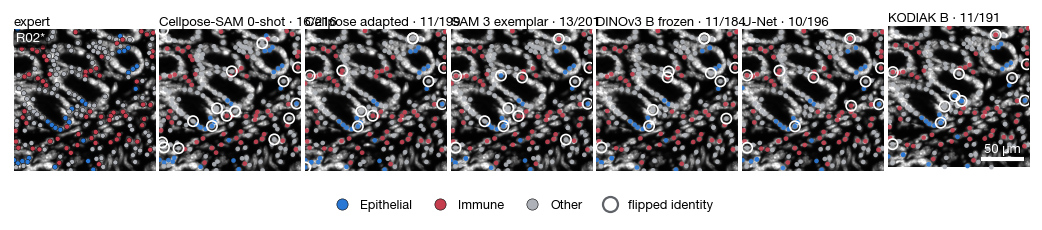

In [5]:
key, (y0, x0), CROP = f"{TEST_SLIDE}_R02", (200, 300), 512
base = norm01(TEST[key]["dapi"])[y0:y0 + CROP, x0:x0 + CROP]
cols = ["expert"] + SHOW
n = len(cols)
fig, axes = plt.subplots(1, n, figsize=(7.6, 7.6 / n + 0.6), squeeze=False)
fig.subplots_adjust(left=0.005, right=0.995, top=0.93, bottom=0.07, wspace=0.03)
inside = lambda d: d[(d.cy > y0) & (d.cy < y0 + CROP) & (d.cx > x0) & (d.cx < x0 + CROP)]
e = inside(expert[expert.region == key])
axes[0, 0].imshow(base, cmap="gray")
axes[0, 0].scatter(e.cx - x0, e.cy - y0, c=[PHENO_COLOR[p] for p in e.pheno], s=7, lw=0.25, edgecolors="black")
axes[0, 0].set_title("expert", fontsize=7, pad=2)
for a, m in zip(axes[0, 1:], SHOW):
    s_ = inside(cells[m][cells[m].region == key])                           # cy, cx: the predicted cell's centroid
    flip = s_[s_.pheno_pred != s_.pheno_expert]
    a.imshow(base * 0.8, cmap="gray")
    a.scatter(s_.cx - x0, s_.cy - y0, c=[PHENO_COLOR[p] for p in s_.pheno_pred], s=6, lw=0, alpha=0.9)
    a.scatter(flip.cx - x0, flip.cy - y0, s=30, facecolors="none", edgecolors="white", lw=0.9)
    a.set_title(f"{SHORT[m]} · {len(flip)}/{len(s_)}", fontsize=7, pad=2)
for a in axes.ravel():
    a.set_axis_off()
chip(axes[0, 0], tag(key))
scalebar(axes[0, -1], CROP)
handles = [plt.Line2D([], [], marker="o", ls="", ms=6, mec="black", mew=0.3, color=v, label=k) for k, v in PHENO_COLOR.items()] + \
          [plt.Line2D([], [], marker="o", ls="", ms=8, mfc="none", mec="#5F6368", mew=1.2, label="flipped identity")]
fig.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.04), fontsize=6.8, handletextpad=0.4, columnspacing=1.2)
plt.show()

**Figure 3 — The phenotype map.** A 512² crop of region R2 of the test slide: expert lineages (left) and, per method, the
lineage each matched cell receives from its predicted boundary, flipped identities circled (title: flipped / matched
cells in the crop).

---
**References.** Hickey et al., *Strategies for accurate cell type identification in
CODEX multiplexed imaging data*, Front. Immunol. 2021 — gating-based cell typing. Bendall et al., Science 2011 — the
log/arcsinh intensity convention. Greenwald et al., Nat. Biotech. 2022 — the error classes.